<a href="https://colab.research.google.com/github/bavucadoz/PCVK-Ganjil-2026/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
NAMA = 'Arya Bayu Samodra'
NIM = '244107020162'
ABSEN = '03'
print(ABSEN, NAMA, NIM)

03 Arya Bayu Samodra 244107020162




---

# **D. PRAKTIKUM MORFOLOGI**



---



In [32]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

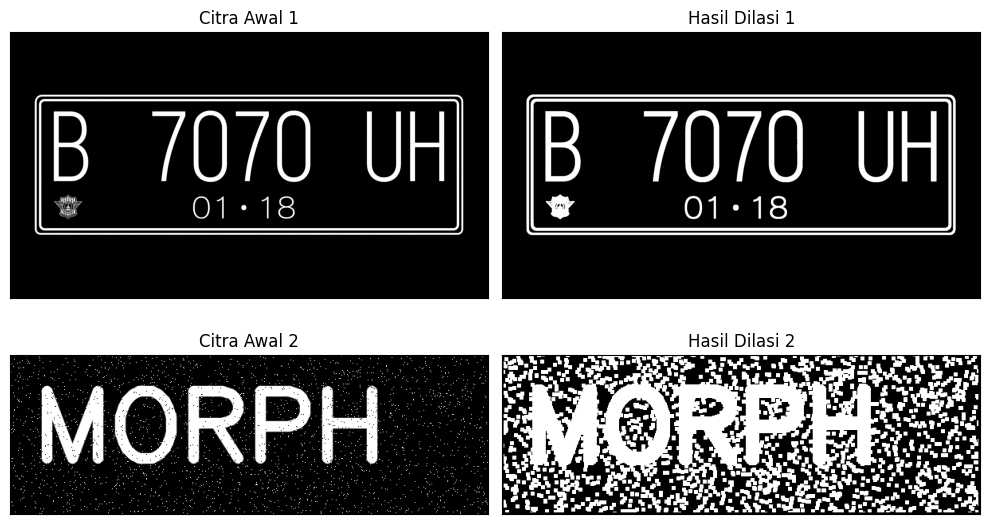

In [28]:
# Fungsi Dilatasi Cross 3x3 Tanpa Library

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED= np.ones((w,w), dtype=np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
w = 5
plt.figure(figsize=(10, 6))

# Perulangan untuk memproses tiap citra
for i, path in enumerate(path_gambar):
    img_d = cv2.imread(path, 0)
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    imgD = dilasi_citra(thresh, w)

    plt.subplot(len(path_gambar), 2, i * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title(f'Citra Awal {i+1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(len(path_gambar), 2, i * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title(f'Hasil Dilasi {i+1}')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Kernel:
[[1 1 1]
 [1 1 1]
 [1 1 1]]


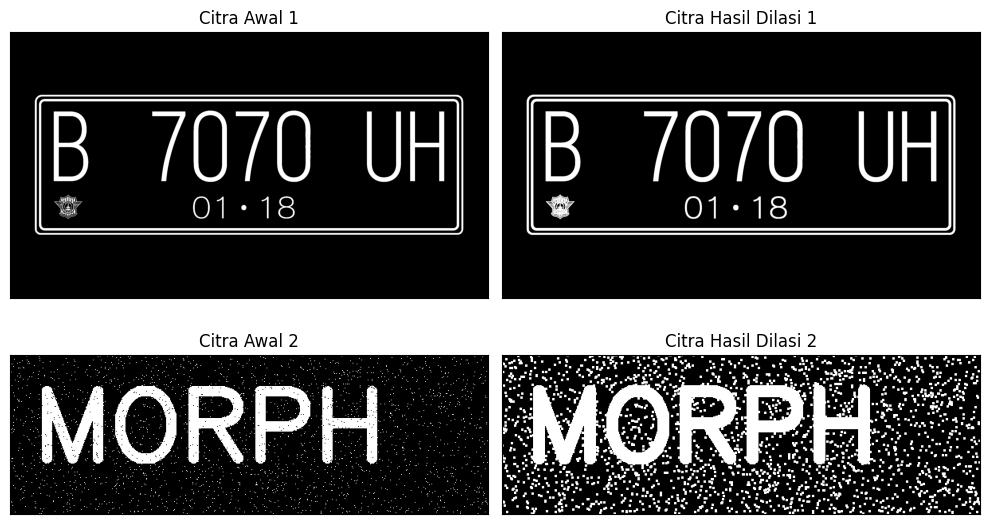

In [35]:
# Dilasi Square 3x3 Dengan Library

path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
kernel = np.ones((3, 3), np.uint8)
print("Kernel:")
print(kernel)

plt.figure(figsize=(10, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)

    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    dilasi = cv2.dilate(thresh, kernel, iterations=1)

    plt.subplot(len(path_gambar), 2, i * 2 + 1)
    plt.imshow(thresh, cmap='gray')
    plt.title(f'Citra Awal {i+1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(len(path_gambar), 2, i * 2 + 2)
    plt.imshow(dilasi, cmap='gray')
    plt.title(f'Citra Hasil Dilasi {i+1}')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

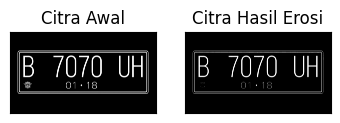

In [23]:
# Erosi Square 5x5 Tanpa Library

def erosi_citra(F,k):
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE= np.ones((k,k), dtype=np.uint8)
  constant= (k-1)//2
  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

img_e= cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k=5
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

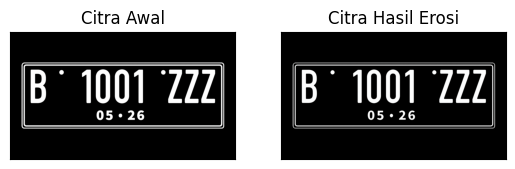

In [14]:
# Erosi Square 5x5 dengan Library

img = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomor.jpg')

kernel = np.ones((5,5),np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

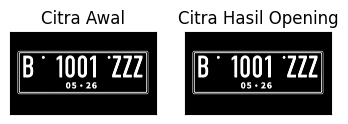

In [17]:
# Operasi Opening Square 3x3 Menggunakan tanpa Library Morphology

img_o= cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomor.jpg',0)
ret, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k=7
imgO = dilasi_citra(erosi_citra(thresho,k),k)

plt.subplot(131),plt.imshow(img_o,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgO,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

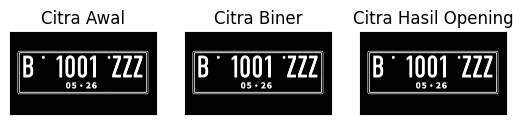

In [18]:
# Operasi Opening Square 3x3 Menggunakan Library Morphology

img = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomor.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
openn = cv2.morphologyEx(thresh,cv2.MORPH_OPEN, kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(openn,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.show()

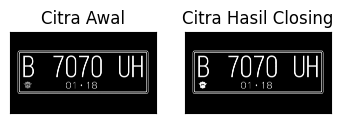

In [20]:
# Operasi Closing Square 3x3 Tanpa dan Menggunakan Library Morphologi

img_c = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',0)
ret, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k=7
imgC = erosi_citra(dilasi_citra(threshc,k),k)

plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgC,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

In [21]:
# Operasi Closing Square 3x3 dengan Menggunakan Library Morphologi

img = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones(())